<a href="https://colab.research.google.com/github/mateosanlu/DeepLearning/blob/main/Laboratorio_Redes_Neruronales_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**LABORATORIO REDES NEURONALES II**

## **Tabla de Contenido**

1.  Laboratorio A. Clasificación Binaria con NumPy - **Pasos 1-10**
2.  Laboratorio B. Red Neuronal Multicapa con NumPy - **Pasos 11-16**
3.  Laboratorio C. Clasificación Binaria con TensorFlow y Keras - **Pasos 17-21**
4.  Laboratorio D. Clasificación Multiclase con TensorFlow y Keras - **Pasos 22-25**
5.  Laboratorio E. Reconocimiento de Dígitos con MNIST y Keras - **Pasos 26-32**
6.  Conclusiones del Laboratorio E
7.  Laboratorio F. Reconocimiento de Dígitos con PyTorch - **Pasos 33-39**
8.  Conclusiones del Laboratorio F
9.  Conclusiones Generales




---
# **LABORATORIO A**
# Clasificación Binaria de Frutas utilizando NumPy

## Objetivo

Comprender el funcionamiento interno de una red neuronal simple implementando manualmente cada etapa del proceso de aprendizaje.

En este laboratorio se construirá una neurona artificial capaz de diferenciar manzanas y bananos a partir de características como peso, longitud y nivel de color amarillo.

El propósito principal es entender cómo funcionan la propagación hacia adelante (Forward Propagation), la función de pérdida (Loss), el algoritmo Backpropagation y la actualización de parámetros sin utilizar frameworks especializados.

## Paso 1. Importación de bibliotecas

En este primer paso se importan las herramientas necesarias para desarrollar el laboratorio.

### NumPy

NumPy permite realizar operaciones matemáticas y manipulaciones matriciales de forma eficiente.

Las redes neuronales trabajan principalmente mediante operaciones sobre vectores y matrices, por lo que esta biblioteca será fundamental durante toda la práctica.

### train_test_split

Esta función permite dividir los datos en conjuntos de entrenamiento y prueba.

### StandardScaler

Se utiliza para normalizar las variables de entrada y evitar que una característica tenga más influencia que otra debido únicamente a su magnitud numérica.

Una vez cargadas correctamente las bibliotecas, el entorno queda preparado para iniciar el procesamiento de datos.

In [40]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("Herramientas cargadas correctamente")


Herramientas cargadas correctamente


## Paso 2. Creación del dataset de frutas

En este paso se construye el conjunto de datos que utilizará la red neuronal.

Cada registro representa una fruta mediante tres características:

- Peso.
- Longitud.
- Nivel de color amarillo.

La matriz X almacena las variables de entrada.

Cada fila representa una fruta diferente y cada columna una característica específica.

El vector y almacena las etiquetas correspondientes:

- 0 = Manzana
- 1 = Banano

Este tipo de problema corresponde a una tarea de clasificación binaria porque únicamente existen dos posibles categorías de salida.

La calidad de los datos es un factor fundamental para el desempeño de cualquier modelo de aprendizaje supervisado.

In [41]:
X = np.array([
    # MANZANAS
    [150, 7.5, 0.10], [160, 8.0, 0.15], [145, 7.2, 0.05],
    [170, 8.3, 0.20], [155, 7.8, 0.10], [165, 8.1, 0.15],
    [140, 7.0, 0.05], [175, 8.5, 0.20], [158, 7.9, 0.10],
    [162, 8.2, 0.15],

    # BANANOS
    [120, 18.0, 0.90], [125, 19.0, 0.95], [115, 17.5, 0.85],
    [130, 20.0, 1.00], [118, 18.5, 0.90], [123, 19.5, 0.95],
    [110, 17.0, 0.80], [128, 20.5, 1.00], [121, 18.8, 0.90],
    [126, 19.2, 0.95]
], dtype=float)

y = np.array([0]*10 + [1]*10).reshape(-1, 1)

print("X:", X.shape)
print("y:", y.shape)


X: (20, 3)
y: (20, 1)


## Paso 3. División del conjunto de datos

Antes de entrenar la red neuronal es necesario separar los datos.

Para ello se generan dos subconjuntos:

### Datos de entrenamiento

Son utilizados para ajustar los pesos del modelo.

### Datos de prueba

Se utilizan exclusivamente para evaluar el desempeño de la red una vez finalizado el entrenamiento.

La división implementada utiliza aproximadamente:

- 80% para entrenamiento.
- 20% para prueba.

Este procedimiento permite estimar la capacidad de generalización del modelo y reduce el riesgo de evaluar la red sobre ejemplos que ya conoce.

In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (16, 3)
X_test: (4, 3)
y_train: (16, 1)
y_test: (4, 1)


## Paso 4. Escalamiento de características

Las características del dataset presentan magnitudes muy diferentes.

Por ejemplo:

- El peso puede tomar valores cercanos a 150.
- La longitud suele encontrarse entre 7 y 20.
- El nivel de amarillo varía entre 0 y 1.

Si estas diferencias no se corrigen, las variables con valores más grandes podrían dominar el proceso de aprendizaje.

Para evitar este problema se utiliza StandardScaler.

Este método transforma las variables para que tengan:

- Media cercana a cero.
- Desviación estándar cercana a uno.

El escalamiento mejora la estabilidad numérica y facilita la convergencia de los algoritmos de optimización.

In [43]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Datos escalados correctamente")
print(X_train[:5])


Datos escalados correctamente
[[ 1.10782916 -0.94158485 -0.93420715]
 [ 1.26848113 -0.95920515 -0.93420715]
 [-1.14129832  0.78520467  0.88863607]
 [-1.24839963  0.87330618  0.88863607]
 [-0.87354505  0.96140768  1.01015895]]


## Paso 5. Definición de la función Sigmoide y función de pérdida

La función Sigmoide transforma cualquier valor numérico en un valor comprendido entre 0 y 1.

Su principal utilidad en este laboratorio consiste en convertir la salida de la neurona en una probabilidad interpretable.

Por ejemplo:

- Valores cercanos a 0 indican Manzana.
- Valores cercanos a 1 indican Banano.

Además, se implementa la función Binary Cross Entropy.

Esta función calcula el error cometido por la red comparando:

- La etiqueta real.
- La probabilidad predicha.

Durante el entrenamiento se espera que el valor del Loss disminuya progresivamente.

Una reducción constante del error indica que el modelo está aprendiendo correctamente.

In [44]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def calcular_error(y_real, y_predicha):
    epsilon = 1e-8
    return -np.mean(
        y_real * np.log(y_predicha + epsilon)
        + (1 - y_real) * np.log(1 - y_predicha + epsilon)
    )


## Paso 6. Inicialización de pesos y primera predicción

Toda red neuronal necesita parámetros iniciales para comenzar el proceso de aprendizaje.

Estos parámetros son:

- Pesos (W).
- Bias (b).

Los pesos se inicializan aleatoriamente con valores pequeños para evitar sesgos iniciales excesivos.

Posteriormente se realiza una primera predicción utilizando dichos parámetros.

Como la red aún no ha aprendido ningún patrón, las probabilidades generadas suelen encontrarse cerca de 0.5.

Esto representa un estado inicial donde la red no posee conocimiento útil sobre el problema.

In [45]:
np.random.seed(42)
W = np.random.randn(3, 1) * 0.01
b = 0.0

Z = X_train @ W + b
A = sigmoid(Z)

print("Pesos iniciales:")
print(W)
print("Primeras predicciones:")
print(A[:5])
print("Error inicial:", calcular_error(y_train, A))


Pesos iniciales:
[[ 0.00496714]
 [-0.00138264]
 [ 0.00647689]]
Primeras predicciones:
[[0.50018847]
 [0.50039405]
 [0.49975024]
 [0.49958679]
 [0.50021859]]
Error inicial: 0.6929322941038263


## Paso 7. Primera iteración de Backpropagation

Backpropagation es el mecanismo que permite a una red neuronal aprender a partir de sus errores.

En este paso se calcula:

- dZ
- dW
- db

Estos valores representan gradientes, es decir, información sobre cómo debe modificarse cada parámetro para reducir el error.

Posteriormente se aplica la tasa de aprendizaje (Learning Rate) para actualizar los pesos y el bias.

Después de esta actualización, la red debería encontrarse ligeramente más cerca de producir predicciones correctas.

In [46]:
dZ = A - y_train

dW = X_train.T @ dZ / len(X_train)
db = np.mean(dZ)

learning_rate = 0.1
W = W - learning_rate * dW
b = b - learning_rate * db

print("Pesos actualizados:")
print(W)
print("Bias actualizado:", b)


Pesos actualizados:
[[-0.04173251]
 [ 0.0483245 ]
 [ 0.05620925]]
Bias actualizado: -2.4020049838036074e-12


## Paso 8. Entrenamiento completo de la neurona

El entrenamiento consiste en repetir continuamente el ciclo de aprendizaje.

Cada época incluye:

1. Forward Propagation.
2. Cálculo del Loss.
3. Backpropagation.
4. Actualización de parámetros.

Conforme aumentan las épocas, la red ajusta progresivamente sus parámetros para reducir el error.

Se monitorea periódicamente el valor de la función de pérdida con el fin de verificar que el entrenamiento avanza correctamente.

Una disminución sostenida del Loss es evidencia de aprendizaje exitoso.

In [47]:
np.random.seed(42)
W = np.random.randn(3, 1) * 0.01
b = 0.0
learning_rate = 0.1
epochs = 2000

for epoch in range(epochs):
    # 1. Forward propagation
    Z = X_train @ W + b
    A = sigmoid(Z)

    # 2. Loss
    error = calcular_error(y_train, A)

    # 3. Backpropagation
    dZ = A - y_train
    dW = X_train.T @ dZ / len(X_train)
    db = np.mean(dZ)

    # 4. Actualización
    W = W - learning_rate * dW
    b = b - learning_rate * db

    if epoch % 400 == 0:
        print("Época:", epoch, "- Error:", round(error, 4))


Época: 0 - Error: 0.6929
Época: 400 - Error: 0.0093
Época: 800 - Error: 0.0046
Época: 1200 - Error: 0.0031
Época: 1600 - Error: 0.0023


## Paso 9. Evaluación sobre datos de prueba

Una vez finalizado el entrenamiento, la red se evalúa con observaciones que no fueron utilizadas durante el aprendizaje.

La evaluación incluye:

- Probabilidades predichas.
- Clases estimadas.
- Accuracy.

Accuracy representa la proporción de predicciones correctas realizadas por el modelo.

Esta métrica permite medir la capacidad de generalización de la neurona frente a ejemplos nuevos.
``

In [48]:
probabilidades = sigmoid(X_test @ W + b)
predicciones = (probabilidades >= 0.5).astype(int)
accuracy = np.mean(predicciones == y_test)

print("Probabilidades:")
print(probabilidades)
print("Predicciones:")
print(predicciones)
print("Respuestas correctas:")
print(y_test)
print("Accuracy:", accuracy)


Probabilidades:
[[5.57638046e-03]
 [8.91035971e-04]
 [9.97758298e-01]
 [9.97877530e-01]]
Predicciones:
[[0]
 [0]
 [1]
 [1]]
Respuestas correctas:
[[0]
 [0]
 [1]
 [1]]
Accuracy: 1.0


## Paso 10. Predicción de una fruta desconocida

Finalmente se introduce una fruta que no pertenece al dataset original.

Antes de realizar la predicción es necesario aplicar exactamente el mismo proceso de escalamiento utilizado durante el entrenamiento.

La red genera una probabilidad asociada a la clase Banano.

Dependiendo del valor obtenido, la observación es clasificada como:

- Manzana.
- Banano.

Este paso simula un escenario real donde un modelo entrenado recibe nuevas observaciones para clasificar.

In [49]:
for i in range(len(predicciones)):
    predicha = "MANZANA" if predicciones[i][0] == 0 else "BANANO"
    real = "MANZANA" if y_test[i][0] == 0 else "BANANO"
    print("Fruta", i + 1, "| Predicción:", predicha, "| Real:", real)

fruta_nueva = np.array([[124, 19.0, 0.94]])
fruta_nueva_escalada = scaler.transform(fruta_nueva)
probabilidad_nueva = sigmoid(fruta_nueva_escalada @ W + b)
resultado = "BANANO" if probabilidad_nueva[0][0] >= 0.5 else "MANZANA"

print("Probabilidad:", probabilidad_nueva[0][0])
print("La red piensa que es:", resultado)


Fruta 1 | Predicción: MANZANA | Real: MANZANA
Fruta 2 | Predicción: MANZANA | Real: MANZANA
Fruta 3 | Predicción: BANANO | Real: BANANO
Fruta 4 | Predicción: BANANO | Real: BANANO
Probabilidad: 0.9980514829516615
La red piensa que es: BANANO


---
# **LABORATORIO B**
# Red Neuronal Multicapa utilizando NumPy

## Objetivo

Comprender cómo una red neuronal multicapa puede aprender patrones más complejos mediante la utilización de neuronas ocultas y funciones de activación no lineales.

A diferencia del laboratorio anterior, la arquitectura ahora estará compuesta por varias capas conectadas entre sí.

## Paso 11. Definición de funciones de activación

En este paso se implementan las funciones necesarias para la red multicapa.

### ReLU

La función ReLU (Rectified Linear Unit) transforma:

- Valores negativos → 0
- Valores positivos → mantienen su valor

Esta función introduce no linealidad y facilita el entrenamiento de redes profundas.

### Derivada de ReLU

Es utilizada durante Backpropagation para calcular correctamente los gradientes.

### Sigmoide

Continúa utilizándose en la capa de salida porque el problema sigue siendo de clasificación binaria.

In [50]:
def relu(z):
    return np.maximum(0, z)

def derivada_relu(z):
    return (z > 0).astype(float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))


## Paso 12. Inicialización de parámetros multicapa

La nueva arquitectura tiene la siguiente estructura:

3 → 4 → 1

Esto significa:

- 3 neuronas de entrada.
- 4 neuronas ocultas.
- 1 neurona de salida.

Se inicializan matrices de pesos independientes para cada capa.

Cada conjunto de parámetros será ajustado durante el entrenamiento mediante Backpropagation.

In [51]:
np.random.seed(42)

W1 = np.random.randn(3, 4) * np.sqrt(2 / 3)
b1 = np.zeros((1, 4))

W2 = np.random.randn(4, 1) * np.sqrt(2 / 4)
b2 = np.zeros((1, 1))

print("W1:", W1.shape)
print("W2:", W2.shape)


W1: (3, 4)
W2: (4, 1)


## Paso 13. Forward Propagation multicapa

En este paso la información fluye desde la entrada hasta la salida.

El recorrido es:

Entrada → Capa Oculta → Capa de Salida

La capa oculta utiliza ReLU para extraer patrones relevantes de los datos.

Posteriormente la salida atraviesa una función Sigmoide que genera una probabilidad asociada a cada clase.

Este proceso constituye la etapa de predicción de la red neuronal.

In [52]:
Z1 = X_train @ W1 + b1
A1 = relu(Z1)

Z2 = A1 @ W2 + b2
A2 = sigmoid(Z2)

print("Salida de la capa oculta:", A1.shape)
print("Primeras probabilidades:")
print(A2[:5])


Salida de la capa oculta: (16, 4)
Primeras probabilidades:
[[0.42911408]
 [0.41367727]
 [0.35607532]
 [0.34175424]
 [0.27437375]]


## Paso 14. Backpropagation multicapa

Una vez calculada la salida se determina el error cometido por la red.

La corrección comienza en la capa de salida y se propaga hacia atrás a través de todas las capas.

Esta propagación inversa permite calcular:

- Gradientes de la capa de salida.
- Gradientes de la capa oculta.

Posteriormente se utilizan estos gradientes para actualizar todos los parámetros del modelo.

Este procedimiento constituye la esencia del aprendizaje en redes neuronales multicapa.

In [53]:
m = len(X_train)

# Capa de salida
dZ2 = A2 - y_train
dW2 = A1.T @ dZ2 / m
db2 = np.mean(dZ2, axis=0, keepdims=True)

# Llevar la señal de corrección hacia la capa oculta
dA1 = dZ2 @ W2.T
dZ1 = dA1 * derivada_relu(Z1)
dW1 = X_train.T @ dZ1 / m
db1 = np.mean(dZ1, axis=0, keepdims=True)


## Paso 15. Entrenamiento de la red multicapa

El entrenamiento repite continuamente las etapas de:

- Forward Propagation.
- Cálculo del error.
- Backpropagation.
- Actualización de pesos.

A medida que transcurren las épocas, la red ajusta progresivamente los patrones internos que utiliza para diferenciar las frutas.

La observación del Loss permite verificar si el modelo está convergiendo adecuadamente.

In [54]:
np.random.seed(42)
W1 = np.random.randn(3, 4) * np.sqrt(2 / 3)
b1 = np.zeros((1, 4))
W2 = np.random.randn(4, 1) * np.sqrt(2 / 4)
b2 = np.zeros((1, 1))

learning_rate = 0.05
epochs = 3000

for epoch in range(epochs):
    # Forward
    Z1 = X_train @ W1 + b1
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Loss
    error = calcular_error(y_train, A2)

    # Backpropagation
    m = len(X_train)
    dZ2 = A2 - y_train
    dW2 = A1.T @ dZ2 / m
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * derivada_relu(Z1)
    dW1 = X_train.T @ dZ1 / m
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # Actualización
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if epoch % 500 == 0:
        print("Época:", epoch, "- Error:", round(error, 4))


Época: 0 - Error: 0.9529
Época: 500 - Error: 0.0555
Época: 1000 - Error: 0.0259
Época: 1500 - Error: 0.0166
Época: 2000 - Error: 0.0122
Época: 2500 - Error: 0.0096


## Paso 16. Evaluación de la red multicapa

Después del entrenamiento se utiliza el conjunto de prueba para evaluar el desempeño del modelo.

La red genera probabilidades para cada observación y posteriormente realiza la clasificación final.

Se calcula nuevamente Accuracy para comparar el desempeño de esta arquitectura frente a la red simple desarrollada previamente.

Los resultados permiten analizar el impacto de incorporar una capa oculta en el proceso de aprendizaje.

In [55]:
Z1_test = X_test @ W1 + b1
A1_test = relu(Z1_test)
Z2_test = A1_test @ W2 + b2
probabilidades_test = sigmoid(Z2_test)

predicciones_multicapa = (probabilidades_test >= 0.5).astype(int)
accuracy_multicapa = np.mean(predicciones_multicapa == y_test)

print("Probabilidades:")
print(probabilidades_test)
print("Predicciones:")
print(predicciones_multicapa)
print("Accuracy:", accuracy_multicapa)


Probabilidades:
[[1.42439384e-02]
 [2.06256532e-05]
 [9.85087119e-01]
 [9.85087119e-01]]
Predicciones:
[[0]
 [0]
 [1]
 [1]]
Accuracy: 1.0


---
# **LABORATORIO C**
# Clasificación Binaria utilizando TensorFlow y Keras

## Objetivo

Implementar una solución equivalente a los laboratorios anteriores utilizando TensorFlow y Keras.

El propósito es comprender cómo los frameworks modernos automatizan procesos matemáticos complejos como el cálculo de gradientes y Backpropagation.

## Paso 17. Construcción de la arquitectura en Keras

Se define una red neuronal utilizando la API Sequential.

La arquitectura implementada es:

3 → 4 → 1

compuesta por:

- Una capa de entrada con tres características.
- Una capa oculta con cuatro neuronas y activación ReLU.
- Una capa de salida con activación Sigmoide.

Esta estructura replica conceptualmente la red multicapa desarrollada manualmente con NumPy.

La instrucción summary() permite visualizar la cantidad de parámetros entrenables presentes en el modelo.

In [56]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(42)

modelo = keras.Sequential([
    keras.layers.Input(shape=(3,)),
    keras.layers.Dense(4, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

modelo.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 4)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21 (84.00 B)

 Trainable params: 21 (84.00 B)

 Non-trainable params: 0 (0.00 B)

## Paso 18. Compilación del modelo

La compilación configura los elementos fundamentales para el entrenamiento.

### Adam

Será responsable de actualizar los pesos utilizando los gradientes calculados automáticamente.

### Binary Cross Entropy

Medirá el error cometido por la red durante la clasificación binaria.

### Accuracy

Permitirá monitorear el porcentaje de predicciones correctas.

Una vez compilado, el modelo queda listo para iniciar el aprendizaje.

In [57]:
modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


## Paso 19. Entrenamiento del modelo

Durante el entrenamiento la red neuronal realiza múltiples iteraciones sobre los datos de entrenamiento.

En cada época ocurre el siguiente proceso:

1. Se realiza una predicción.
2. Se calcula el error.
3. Se ejecuta Backpropagation automáticamente.
4. Se actualizan los pesos.

La ventaja principal de Keras es que estos pasos se realizan internamente mediante el método `fit()`.

Al finalizar, se analizan los valores iniciales y finales de la función de pérdida para comprobar si el aprendizaje fue exitoso.

In [58]:
historial = modelo.fit(
    X_train,
    y_train,
    epochs=200,
    verbose=0
)

print("Error inicial:", historial.history["loss"][0])
print("Error final:", historial.history["loss"][-1])


Error inicial: 0.48413586616516113
Error final: 0.002654340351000428


## Paso 20. Evaluación y visualización del aprendizaje

En este paso se analiza el comportamiento del entrenamiento mediante una gráfica del error.

Si el modelo está aprendiendo correctamente, el Loss debería disminuir progresivamente conforme aumentan las épocas.

Posteriormente se realiza una evaluación utilizando el conjunto de prueba.

Las métricas obtenidas permiten medir:

- La capacidad de generalización del modelo.
- La precisión alcanzada sobre datos no utilizados durante el entrenamiento.

Un buen modelo debe presentar un Accuracy alto y un Loss relativamente bajo.

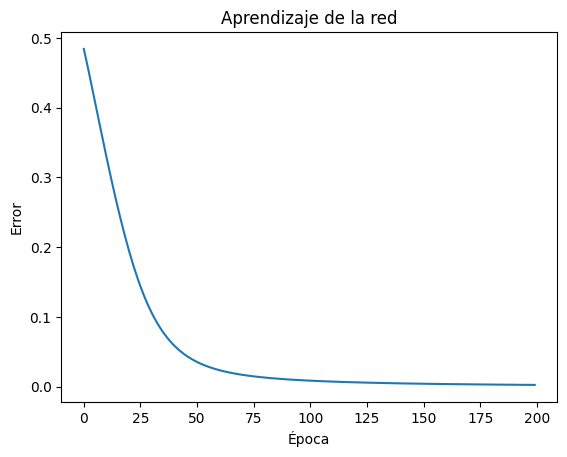

Error en prueba: 0.0023548509925603867
Accuracy: 1.0


In [59]:
import matplotlib.pyplot as plt

plt.plot(historial.history["loss"])
plt.title("Aprendizaje de la red")
plt.xlabel("Época")
plt.ylabel("Error")
plt.show()

test_loss, test_accuracy = modelo.evaluate(X_test, y_test, verbose=0)
print("Error en prueba:", test_loss)
print("Accuracy:", test_accuracy)


## Paso 21. Predicción de una nueva observación

Una vez entrenado el modelo, se utiliza para clasificar una fruta que nunca fue observada durante el proceso de entrenamiento.

Antes de realizar la predicción es necesario aplicar exactamente el mismo escalamiento utilizado anteriormente.

Este procedimiento garantiza que las nuevas observaciones mantengan la misma distribución estadística que los datos de entrenamiento.

Finalmente, la red devuelve una probabilidad que se interpreta como la confianza de pertenencia a cada clase.

In [60]:
fruta_nueva = np.array([[124, 19.0, 0.94]])
fruta_nueva_escalada = scaler.transform(fruta_nueva)

probabilidad = modelo.predict(fruta_nueva_escalada, verbose=0)
resultado = "BANANO" if probabilidad[0][0] >= 0.5 else "MANZANA"

print("Probabilidad:", probabilidad[0][0])
print("La red piensa que es:", resultado)


Probabilidad: 0.998354
La red piensa que es: BANANO


---
# **LABORATORIO D**
# Clasificación Multiclase con TensorFlow y Keras

## Objetivo

Extender el problema de clasificación binaria hacia un problema de clasificación multiclase.

En este laboratorio la red neuronal deberá identificar tres tipos diferentes de frutas:

- Manzana
- Banano
- Naranja

Para resolver este escenario se utilizará la función de activación Softmax.

## Paso 22. Creación del dataset multiclase

En esta etapa se amplía el conjunto de datos incorporando una nueva categoría: naranja.

Cada registro continúa describiéndose mediante:

- Peso.
- Longitud.
- Nivel de color amarillo.

Sin embargo, ahora existen tres posibles resultados:

- Clase 0 → Manzana.
- Clase 1 → Banano.
- Clase 2 → Naranja.

Este cambio transforma el problema en una tarea de clasificación multiclase.

In [61]:
X_multi = np.array([
    # MANZANAS - 0
    [150,7.5,.10],[160,8.0,.15],[145,7.2,.05],[170,8.3,.20],[155,7.8,.10],
    [165,8.1,.15],[140,7.0,.05],[175,8.5,.20],[158,7.9,.10],[162,8.2,.15],

    # BANANOS - 1
    [120,18.0,.90],[125,19.0,.95],[115,17.5,.85],[130,20.0,1.00],[118,18.5,.90],
    [123,19.5,.95],[110,17.0,.80],[128,20.5,1.00],[121,18.8,.90],[126,19.2,.95],

    # NARANJAS - 2
    [180,8.0,.35],[190,8.5,.40],[175,7.8,.30],[200,9.0,.45],[185,8.2,.35],
    [195,8.7,.40],[170,7.5,.30],[205,9.2,.45],[188,8.4,.35],[192,8.6,.40]
], dtype=float)

y_multi = np.array([0]*10 + [1]*10 + [2]*10)


## Paso 23. División y normalización de los datos

El conjunto de datos se divide en dos grupos:

- Entrenamiento.
- Prueba.

Posteriormente se realiza un proceso de estandarización utilizando StandardScaler.

La normalización es importante para garantizar que todas las variables contribuyan de manera equilibrada durante el aprendizaje.

Este procedimiento favorece una convergencia más rápida y estable.


In [62]:
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi,
    y_multi,
    test_size=0.2,
    random_state=42,
    stratify=y_multi
)

scaler_multi = StandardScaler()
X_train_multi = scaler_multi.fit_transform(X_train_multi)
X_test_multi = scaler_multi.transform(X_test_multi)


## Paso 24. Construcción de la red multiclase

La arquitectura propuesta está compuesta por:

- 3 variables de entrada.
- 6 neuronas ocultas con ReLU.
- 3 neuronas de salida con Softmax.

Cada neurona de salida representa una clase diferente.

A diferencia de la clasificación binaria, aquí no interesa únicamente la probabilidad de una clase, sino una distribución completa de probabilidades para todas las categorías disponibles.

Softmax permite precisamente generar esta distribución.

In [63]:
tf.random.set_seed(42)

modelo_multi = keras.Sequential([
    keras.layers.Input(shape=(3,)),
    keras.layers.Dense(6, activation="relu"),
    keras.layers.Dense(3, activation="softmax")
])

modelo_multi.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


## Paso 25. Entrenamiento y evaluación del modelo

Después de definir la arquitectura se inicia el proceso de entrenamiento.

Durante este proceso la red aprende a distinguir patrones característicos de cada fruta.

Una vez finalizado el entrenamiento se calculan:

- Accuracy.
- Predicciones.
- Comparación con etiquetas reales.

Finalmente se realiza una prueba con una nueva fruta para verificar la capacidad de generalización del modelo.

La clase seleccionada corresponde al índice que presenta la mayor probabilidad calculada por Softmax.

In [64]:
historial_multi = modelo_multi.fit(
    X_train_multi,
    y_train_multi,
    epochs=300,
    verbose=0
)

loss_multi, accuracy_multi = modelo_multi.evaluate(
    X_test_multi,
    y_test_multi,
    verbose=0
)

probabilidades_multi = modelo_multi.predict(X_test_multi, verbose=0)
predicciones_multi = np.argmax(probabilidades_multi, axis=1)

print("Accuracy:", accuracy_multi)
print("Predicciones:", predicciones_multi)
print("Reales:", y_test_multi)

nombres_frutas = ["MANZANA", "BANANO", "NARANJA"]
fruta_nueva_multi = np.array([[190, 8.5, 0.38]])
fruta_nueva_multi = scaler_multi.transform(fruta_nueva_multi)
prob = modelo_multi.predict(fruta_nueva_multi, verbose=0)
clase = np.argmax(prob, axis=1)[0]
print("La red piensa que es:", nombres_frutas[clase])


Accuracy: 1.0
Predicciones: [2 1 2 0 1 0]
Reales: [2 1 2 0 1 0]
La red piensa que es: NARANJA


---
# **LABORATORIO E**
# Clasificación de Dígitos con MNIST utilizando TensorFlow y Keras

## Objetivo

Aplicar los fundamentos del Deep Learning en un problema real de reconocimiento de patrones utilizando el dataset MNIST.

En este laboratorio se construirá una red neuronal multicapa capaz de identificar dígitos escritos a mano, utilizando TensorFlow y Keras como framework principal.

A diferencia de los ejercicios anteriores, donde se trabajó con características tabulares de frutas, ahora se procesarán imágenes que representan los números del 0 al 9.

La arquitectura utilizada será una red neuronal densa (Fully Connected Network) sin emplear redes convolucionales, cumpliendo con las restricciones de la actividad.

## Paso 26. Carga del dataset MNIST

En este paso se carga el dataset MNIST utilizando las herramientas incorporadas de Keras.

MNIST es uno de los conjuntos de datos más utilizados para la enseñanza y evaluación de algoritmos de aprendizaje automático debido a su simplicidad y valor educativo.

El dataset contiene:

- 60.000 imágenes para entrenamiento.
- 10.000 imágenes para prueba.
- Imágenes en escala de grises.
- Resolución de 28 × 28 píxeles.
- Etiquetas correspondientes a los dígitos del 0 al 9.

Las variables obtenidas son:

### x_train_mnist

Contiene las imágenes utilizadas para entrenar la red neuronal.

### y_train_mnist

Contiene las etiquetas reales correspondientes a las imágenes de entrenamiento.

### x_test_mnist

Contiene las imágenes reservadas para evaluación.

### y_test_mnist

Contiene las etiquetas reales de las imágenes de prueba.

La impresión de las dimensiones permite verificar que el dataset fue cargado correctamente antes de continuar con el procesamiento.

In [65]:
from tensorflow import keras
import numpy as np

(x_train_mnist, y_train_mnist), (x_test_mnist, y_test_mnist) =     keras.datasets.mnist.load_data()

print("Entrenamiento:", x_train_mnist.shape, y_train_mnist.shape)
print("Prueba:", x_test_mnist.shape, y_test_mnist.shape)


Entrenamiento: (60000, 28, 28) (60000,)
Prueba: (10000, 28, 28) (10000,)


## Paso 27. Visualización de imágenes y normalización

Antes de entrenar el modelo es importante inspeccionar visualmente una muestra del dataset.

La visualización permite comprobar que las etiquetas coinciden con el contenido real de las imágenes y facilita la comprensión del problema que resolverá la red neuronal.

Posteriormente se realiza un proceso de normalización.

Originalmente, los píxeles tienen valores entre:

0 y 255

donde:

- 0 representa negro.
- 255 representa blanco.

Estos valores son transformados al rango:

0 y 1

mediante la división por 255.

### Importancia de la normalización

La normalización ofrece varias ventajas:

- Reduce diferencias de escala entre variables.
- Mejora la estabilidad de los cálculos numéricos.
- Facilita el cálculo de gradientes.
- Acelera el entrenamiento.
- Favorece la convergencia del modelo.

Después de esta transformación, la red neuronal recibe datos más adecuados para el aprendizaje.

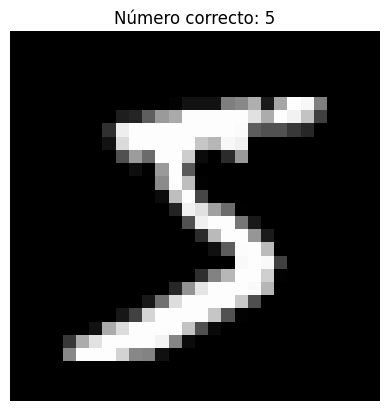

Mínimo: 0.0
Máximo: 1.0


In [66]:
import matplotlib.pyplot as plt

plt.imshow(x_train_mnist[0], cmap="gray")
plt.title(f"Número correcto: {y_train_mnist[0]}")
plt.axis("off")
plt.show()

x_train_mnist = x_train_mnist.astype("float32") / 255.0
x_test_mnist = x_test_mnist.astype("float32") / 255.0

print("Mínimo:", x_train_mnist.min())
print("Máximo:", x_train_mnist.max())


## Paso 28. Construcción de la arquitectura neuronal

Una vez preparados los datos, se procede a definir la estructura de la red neuronal.

La arquitectura seleccionada es:

784 → 128 → 10

### Capa Flatten

Las imágenes tienen dimensión:

28 × 28

Sin embargo, las capas densas trabajan con vectores unidimensionales.

Por esta razón se utiliza una capa Flatten que transforma cada imagen en un vector de:

784 características.

Este valor surge de:

28 × 28 = 784

### Capa oculta

La red incorpora una capa densa de 128 neuronas con función de activación ReLU.

Su función consiste en aprender representaciones internas y patrones relevantes presentes en las imágenes.

### Capa de salida

La capa final contiene 10 neuronas y utiliza la función Softmax.

Cada neurona representa una de las posibles clases:

- 0
- 1
- 2
- 3
- 4
- 5
- 6
- 7
- 8
- 9

Softmax convierte la salida de la red en una distribución de probabilidades cuya suma es igual a 1.

El modelo seleccionará como predicción la clase con la probabilidad más alta.

Es importante resaltar que esta arquitectura utiliza únicamente capas densas y no emplea capas convolucionales.

In [67]:
import tensorflow as tf

tf.random.set_seed(42)

modelo_mnist = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])

modelo_mnist.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Paso 29. Compilación y entrenamiento del modelo

Antes de iniciar el aprendizaje es necesario configurar el proceso de entrenamiento.

### Optimizador Adam

Adam es un algoritmo ampliamente utilizado en Deep Learning porque adapta automáticamente la velocidad de aprendizaje de cada parámetro.

Esto suele producir una convergencia más rápida y estable.

### Función de pérdida

Se utiliza Sparse Categorical Crossentropy.

Esta función es adecuada para problemas de clasificación multiclase donde las etiquetas están codificadas como números enteros.

Su objetivo es medir la diferencia entre:

- Las clases reales.
- Las probabilidades generadas por la red.

### Accuracy

Accuracy representa el porcentaje de predicciones correctas realizadas por el modelo.

Es la principal métrica de evaluación utilizada en esta práctica.

### Entrenamiento

Durante cada época se ejecutan los siguientes procesos:

1. Forward Propagation.
2. Cálculo del error.
3. Backpropagation.
4. Actualización de parámetros.

Este ciclo se repite varias veces hasta que la red logra aprender patrones útiles para distinguir los diferentes dígitos.

In [68]:
modelo_mnist.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

historial_mnist = modelo_mnist.fit(
    x_train_mnist,
    y_train_mnist,
    epochs=5,
    validation_split=0.1
)


Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9231 - loss: 0.2689 - val_accuracy: 0.9638 - val_loss: 0.1229
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9644 - loss: 0.1200 - val_accuracy: 0.9710 - val_loss: 0.0992
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9758 - loss: 0.0823 - val_accuracy: 0.9768 - val_loss: 0.0857
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9822 - loss: 0.0608 - val_accuracy: 0.9773 - val_loss: 0.0838
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9872 - loss: 0.0456 - val_accuracy: 0.9775 - val_loss: 0.0839


## Paso 30. Visualización de Loss y Accuracy

Una vez finalizado el entrenamiento se generan gráficas para analizar el comportamiento del modelo.

### Curva de Loss

La función Loss refleja el error cometido por la red neuronal.

Durante un entrenamiento satisfactorio se espera observar:

- Un valor alto al inicio.
- Una reducción progresiva.
- Una tendencia a estabilizarse hacia el final.

La disminución del Loss indica que el modelo está mejorando sus predicciones.

### Curva de Accuracy

La precisión muestra el porcentaje de ejemplos correctamente clasificados.

Durante el aprendizaje normalmente se observa:

- Accuracy bajo en las primeras épocas.
- Incremento gradual conforme avanza el entrenamiento.
- Estabilización cerca del valor máximo alcanzable por el modelo.

### Interpretación conjunta

Analizar ambas curvas permite comprender la evolución del aprendizaje y detectar posibles problemas de entrenamiento antes de realizar la evaluación final.

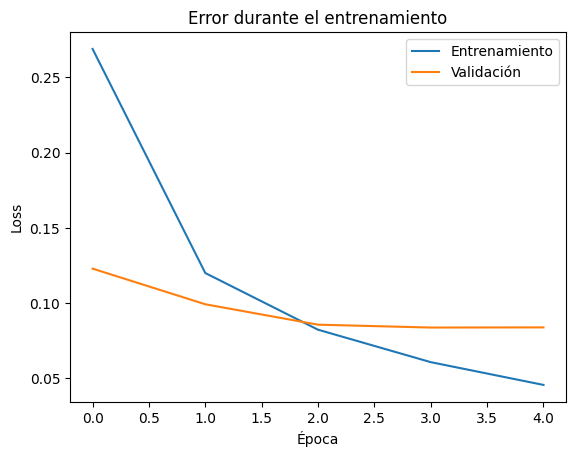

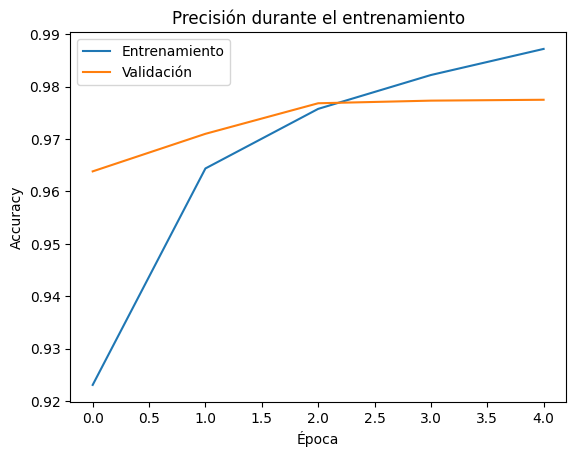

In [69]:
plt.plot(historial_mnist.history["loss"], label="Entrenamiento")
plt.plot(historial_mnist.history["val_loss"], label="Validación")
plt.title("Error durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(historial_mnist.history["accuracy"], label="Entrenamiento")
plt.plot(historial_mnist.history["val_accuracy"], label="Validación")
plt.title("Precisión durante el entrenamiento")
plt.xlabel("Época")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


## Paso 31. Evaluación del modelo y generación de predicciones

Después del entrenamiento se evalúa el modelo utilizando el conjunto de prueba.

Estas imágenes nunca fueron utilizadas para ajustar los pesos de la red.

Por esta razón proporcionan una medida más realista del desempeño del sistema.

Las métricas obtenidas son:

### Test Loss

Representa el error promedio sobre las imágenes de prueba.

### Test Accuracy

Indica el porcentaje de imágenes clasificadas correctamente.

Posteriormente se generan predicciones para las primeras imágenes del conjunto de prueba.

Cada predicción se compara con la etiqueta real correspondiente, permitiendo verificar el funcionamiento general del clasificador.

In [70]:
test_loss_mnist, test_accuracy_mnist = modelo_mnist.evaluate(
    x_test_mnist,
    y_test_mnist,
    verbose=0
)

print("Error de prueba:", test_loss_mnist)
print("Accuracy de prueba:", test_accuracy_mnist)

predicciones_mnist = modelo_mnist.predict(x_test_mnist[:10], verbose=0)

for i in range(10):
    prediccion = np.argmax(predicciones_mnist[i])
    print("Imagen", i + 1, "| Real:", y_test_mnist[i], "| Predicción:", prediccion)


Error de prueba: 0.08354276418685913
Accuracy de prueba: 0.9750999808311462
Imagen 1 | Real: 7 | Predicción: 7
Imagen 2 | Real: 2 | Predicción: 2
Imagen 3 | Real: 1 | Predicción: 1
Imagen 4 | Real: 0 | Predicción: 0
Imagen 5 | Real: 4 | Predicción: 4
Imagen 6 | Real: 1 | Predicción: 1
Imagen 7 | Real: 4 | Predicción: 4
Imagen 8 | Real: 9 | Predicción: 9
Imagen 9 | Real: 5 | Predicción: 5
Imagen 10 | Real: 9 | Predicción: 9


## Paso 32. Análisis de errores del modelo

Un modelo con alta precisión no necesariamente clasifica correctamente todas las observaciones.

Por esta razón se realiza una búsqueda explícita de ejemplos mal clasificados.

El procedimiento consiste en:

1. Generar predicciones para todas las imágenes de prueba.
2. Comparar cada predicción con su etiqueta real.
3. Identificar las posiciones donde existe discrepancia.

Una vez localizado un error, se visualiza la imagen correspondiente.

### Importancia del análisis de errores

El análisis de errores permite:

- Comprender limitaciones del modelo.
- Identificar patrones difíciles de clasificar.
- Detectar posibles ambigüedades visuales.
- Evaluar oportunidades de mejora.

Este proceso demuestra que el desempeño de una red neuronal no debe juzgarse únicamente mediante Accuracy, sino también mediante el estudio de casos específicos de éxito y fracaso.

Cantidad de errores: 249


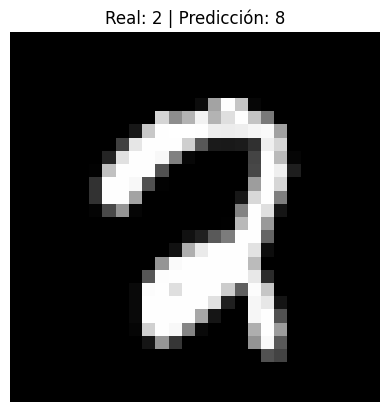

In [71]:
predicciones_todas = modelo_mnist.predict(x_test_mnist, verbose=0)
clases_predichas = np.argmax(predicciones_todas, axis=1)
errores = np.where(clases_predichas != y_test_mnist)[0]

print("Cantidad de errores:", len(errores))

indice_error = errores[0]
plt.imshow(x_test_mnist[indice_error], cmap="gray")
plt.title(
    f"Real: {y_test_mnist[indice_error]} | "
    f"Predicción: {clases_predichas[indice_error]}"
)
plt.axis("off")
plt.show()


# Conclusiones del Laboratorio E
# Clasificación de Dígitos con TensorFlow y Keras

A partir de la implementación desarrollada con TensorFlow y Keras fue posible aplicar los conceptos fundamentales del aprendizaje supervisado a un problema real de reconocimiento de imágenes.

La utilización del dataset MNIST permitió observar cómo una red neuronal es capaz de aprender patrones presentes en los píxeles de las imágenes para identificar correctamente los dígitos escritos a mano.

Durante el proceso de entrenamiento se evidenció la disminución progresiva de la función de pérdida y el incremento de la precisión, lo cual indica que el modelo logró extraer características relevantes de los datos.

Asimismo, se comprobó la importancia de la normalización de los datos de entrada, ya que esta etapa contribuye significativamente a la estabilidad y eficiencia del entrenamiento.

Finalmente, el análisis de predicciones y errores permitió comprender que incluso modelos con altos niveles de precisión pueden presentar dificultades ante ejemplos ambiguos o visualmente complejos, resaltando la importancia de evaluar no solo las métricas globales sino también casos individuales de clasificación.

---
# **LABORATORIO F**
# Clasificación de Dígitos con MNIST utilizando PyTorch

## Objetivo

Replicar el problema de clasificación de dígitos utilizando PyTorch.

La finalidad es comprender cómo un framework alternativo implementa los mismos fundamentos matemáticos estudiados previamente.

A diferencia de Keras, PyTorch permite observar y controlar explícitamente gran parte del ciclo de entrenamiento, facilitando la comprensión de conceptos como gradientes, optimización y retropropagación.

## Paso 33. Carga del dataset MNIST en PyTorch

En este paso se importan las bibliotecas necesarias para trabajar con PyTorch.

Posteriormente se descarga el dataset MNIST y se crean los objetos Dataset correspondientes.

La transformación ToTensor convierte automáticamente cada imagen en un tensor compatible con las operaciones de PyTorch.

Los conjuntos generados son:

- train_dataset
- test_dataset

Estos objetos almacenan tanto las imágenes como sus respectivas etiquetas y permiten acceder a ellas de manera eficiente durante el entrenamiento.

In [79]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)


## Paso 34. Creación de DataLoaders

Los DataLoaders son responsables de suministrar los datos a la red neuronal durante el entrenamiento.

Su función principal consiste en dividir el dataset en pequeños lotes denominados batches.

En este laboratorio se utiliza un tamaño de lote de 64 imágenes.

### Ventajas de utilizar batches

- Menor consumo de memoria.
- Entrenamiento más eficiente.
- Actualizaciones más frecuentes de los pesos.
- Mejor aprovechamiento de recursos computacionales.

Además, el parámetro shuffle=True reorganiza las observaciones en cada época, evitando que la red aprenda dependencias relacionadas con el orden de los datos.

In [80]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


## Paso 35. Definición de la arquitectura neuronal

La arquitectura implementada es equivalente a la utilizada anteriormente con Keras:

784 → 128 → 10

La red hereda de la clase nn.Module, la base de todos los modelos en PyTorch.

La estructura contiene:

### Flatten

Convierte cada imagen de 28 × 28 píxeles en un vector de 784 características.

### Primera capa densa

Recibe los 784 valores de entrada y genera 128 activaciones.

### Función ReLU

Introduce no linealidad dentro del modelo.

### Capa de salida

Genera diez valores de salida, correspondientes a las diez clases posibles.

Estos valores serán utilizados posteriormente por la función de pérdida para calcular el error del modelo.

In [81]:
class RedMNIST(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.capa1 = nn.Linear(784, 128)
        self.relu = nn.ReLU()
        self.salida = nn.Linear(128, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.capa1(x)
        x = self.relu(x)
        x = self.salida(x)
        return x

modelo_pytorch = RedMNIST()
print(modelo_pytorch)


RedMNIST(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (capa1): Linear(in_features=784, out_features=128, bias=True)
  (relu): ReLU()
  (salida): Linear(in_features=128, out_features=10, bias=True)
)


## Paso 36. Definición de la función de pérdida y optimizador

Todo modelo supervisado necesita un mecanismo para cuantificar el error y otro para corregir los parámetros.

### CrossEntropyLoss

Calcula el error para problemas de clasificación multiclase.

La pérdida será menor cuando las predicciones estén más próximas a las etiquetas reales.

### Adam

Es el algoritmo encargado de actualizar los pesos utilizando los gradientes generados durante el entrenamiento.

La combinación de CrossEntropyLoss y Adam constituye una de las configuraciones más utilizadas en problemas de clasificación de imágenes.

In [82]:
criterio = nn.CrossEntropyLoss()

optimizador = optim.Adam(
    modelo_pytorch.parameters(),
    lr=0.001
)

print("Modelo, criterio y optimizador listos")


Modelo, criterio y optimizador listos


## Paso 37. Entrenamiento de la red neuronal

En este paso se implementa explícitamente el ciclo de entrenamiento.

Para cada lote de imágenes se ejecutan las siguientes operaciones:

### Reinicio de gradientes

Se eliminan los gradientes calculados en iteraciones anteriores.

### Forward Propagation

Las imágenes atraviesan la red produciendo una predicción.

### Cálculo del error

Se compara la salida del modelo con las etiquetas reales.

### Backpropagation

La instrucción:

error.backward()

calcula automáticamente los gradientes de todos los parámetros entrenables.

### Actualización de pesos

La instrucción:

optimizador.step()

modifica los parámetros utilizando los gradientes calculados.

Al finalizar cada época se imprime el error promedio para monitorear la evolución del aprendizaje.

In [83]:
epochs = 3

for epoch in range(epochs):
    modelo_pytorch.train()
    error_total = 0

    for imagenes, etiquetas in train_loader:
        # 1. Limpiar gradientes anteriores
        optimizador.zero_grad()

        # 2. Forward
        salidas = modelo_pytorch(imagenes)

        # 3. Loss
        error = criterio(salidas, etiquetas)

        # 4. Backpropagation
        error.backward()

        # 5. Actualizar pesos
        optimizador.step()

        error_total += error.item()

    promedio_error = error_total / len(train_loader)
    print("Época:", epoch + 1, "- Error:", round(promedio_error, 4))


Época: 1 - Error: 0.3453
Época: 2 - Error: 0.1574
Época: 3 - Error: 0.1105


## Paso 38. Evaluación del modelo

Después del entrenamiento se evalúa el desempeño utilizando el conjunto de prueba.

Durante este proceso se desactiva el cálculo de gradientes mediante:

torch.no_grad()

Esto reduce el consumo de memoria y acelera la ejecución.

La red procesa todas las imágenes de prueba y genera una predicción para cada una.

Finalmente se calcula el Accuracy, que representa la proporción de imágenes clasificadas correctamente respecto al total evaluado.

In [84]:
modelo_pytorch.eval()
correctas = 0
total = 0

with torch.no_grad():
    for imagenes, etiquetas in test_loader:
        salidas = modelo_pytorch(imagenes)
        _, predicciones = torch.max(salidas, 1)
        total += etiquetas.size(0)
        correctas += (predicciones == etiquetas).sum().item()

accuracy_pytorch = correctas / total
print("Accuracy en prueba:", accuracy_pytorch)


Accuracy en prueba: 0.9689


## Paso 39. Predicción individual de una imagen

Como evidencia final del funcionamiento del modelo se selecciona una imagen específica del conjunto de prueba.

Esta imagen es procesada por la red neuronal entrenada y se obtiene una predicción.

Posteriormente se comparan:

- Etiqueta real.
- Etiqueta predicha.

Además, se visualiza gráficamente la imagen para facilitar la interpretación de los resultados.

Este paso permite observar de forma práctica cómo una red neuronal entrenada es capaz de reconocer patrones visuales y asociarlos con una clase específica.

Número real: 7
Número predicho: 7


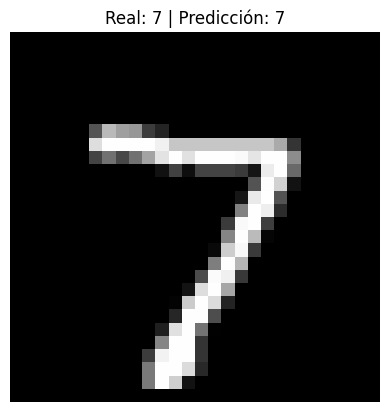

In [85]:
imagen, etiqueta_real = test_dataset[0]
entrada = imagen.unsqueeze(0)

modelo_pytorch.eval()
with torch.no_grad():
    salida = modelo_pytorch(entrada)
    prediccion = torch.argmax(salida, dim=1).item()

print("Número real:", etiqueta_real)
print("Número predicho:", prediccion)

plt.imshow(imagen.squeeze(), cmap="gray")
plt.title(f"Real: {etiqueta_real} | Predicción: {prediccion}")
plt.axis("off")
plt.show()


# Conclusiones del Laboratorio F
# Clasificación de Dígitos con PyTorch

La implementación de la red neuronal utilizando PyTorch permitió comprender de manera más detallada el funcionamiento interno del proceso de entrenamiento de un modelo de Deep Learning.

A diferencia de TensorFlow y Keras, donde gran parte del proceso se encuentra automatizado, PyTorch ofrece un mayor nivel de control sobre cada etapa del aprendizaje, incluyendo el cálculo de gradientes, la retropropagación del error y la actualización de parámetros.

Durante el desarrollo de la práctica se observó cómo los métodos `backward()` y `step()` constituyen elementos fundamentales para la optimización de los pesos de la red neuronal.

Los resultados obtenidos demostraron que PyTorch puede alcanzar desempeños similares a los obtenidos con Keras utilizando arquitecturas equivalentes.

Además, el uso de DataLoaders y procesamiento por lotes permitió entrenar el modelo de forma eficiente y organizada.

En conclusión, PyTorch representa una herramienta flexible y poderosa para el desarrollo de modelos de Deep Learning, especialmente en proyectos donde se requiere un control más detallado sobre el proceso de entrenamiento.


# Conclusiones Generales

Durante el desarrollo de la práctica Redes Neuronales II se logró profundizar en los fundamentos matemáticos y computacionales que permiten el funcionamiento de las redes neuronales artificiales.

Inicialmente se implementaron modelos neuronales básicos desde cero utilizando NumPy, lo que permitió comprender directamente conceptos como Forward Propagation, cálculo de error, funciones de activación y Backpropagation.

Posteriormente se comprobó cómo las redes multicapa pueden aprender relaciones más complejas mediante la incorporación de capas ocultas y funciones de activación como ReLU.

Asimismo, se analizaron las diferencias entre problemas de clasificación binaria y clasificación multiclase, utilizando Sigmoide para problemas de dos clases y Softmax para escenarios con múltiples categorías.

El trabajo con TensorFlow, Keras y PyTorch permitió evidenciar que, aunque cada framework posee una sintaxis diferente, todos implementan los mismos principios fundamentales de aprendizaje supervisado.

La utilización del dataset MNIST permitió trasladar los conocimientos adquiridos a un problema real de reconocimiento de imágenes, demostrando la capacidad de las redes neuronales para identificar patrones complejos a partir de datos visuales.

Otro aspecto relevante fue la observación del comportamiento de métricas como Loss y Accuracy, las cuales permitieron monitorear el proceso de aprendizaje y evaluar objetivamente el desempeño de los modelos desarrollados.

Finalmente, la práctica permitió comprender que el éxito de un modelo de Deep Learning no depende únicamente de la arquitectura utilizada, sino también de etapas fundamentales como la preparación de datos, normalización, selección de funciones de activación, optimización y análisis de resultados.

En conclusión, los objetivos planteados para la actividad fueron alcanzados satisfactoriamente, logrando implementar y evaluar diferentes arquitecturas neuronales utilizando herramientas modernas de Inteligencia Artificial y Aprendizaje Profundo.